## this notebook creates transects displaying T & S, with isopycnals

In [1]:
# Import packages
import os              # For file path handling
import time            # For sleep during retry logic
import shutil          # For copying downloaded content
import requests        # For HTTP downloads
import urllib3         # For disabling SSL warnings
import numpy as np     # For logical operations and array handling
import pandas as pd    # For reading and manipulating the GDAC index
from datetime import datetime  # For date filtering
import xarray as xr 
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import cmocean
import gsw as gsw
import numpy as np
from pathlib import Path
import cmocean

In [2]:
os.chdir(r'C:\Users\nribeiro\OneDrive - University of Tasmania\IMOS Shared Docs\CAPSTAN 2025\Datasets\CTD KI') #Will need to change this 

In [3]:
# Find the KI CTD files
files_ki = sorted(Path(".").glob("in2026_t02*CtdAvg.nc"))

print(f"Found {len(files_ki)} files:")
for f in files_ki:
    print(f.name)

Found 5 files:
in2026_t02005CtdAvg.nc
in2026_t02006CtdAvg.nc
in2026_t02007CtdAvg.nc
in2026_t02008CtdAvg.nc
in2026_t02009CtdAvg.nc


In [4]:
station_data_ki = []

for f in files_ki:
    ds_ki = xr.open_dataset(f)

    station = int(f.name.split("CtdAvg")[0][-3:])

    print(f"\nStation {station}")
    print("Temperature:", ds_ki["temperature"].shape)
    print("Salinity:", ds_ki["salinity"].shape)
    print("Pressure:", ds_ki["pressure"].shape)
    print("Latitude:", ds_ki["latitude"].values.squeeze())
    print("Longitude:", ds_ki["longitude"].values.squeeze())

    station_data_ki.append({
        "station": station,
        "lat": float(ds_ki["latitude"].values.squeeze()),
        "lon": float(ds_ki["longitude"].values.squeeze()),
        "pressure": ds_ki["pressure"].values.squeeze(),
        "temperature": ds_ki["temperature"].values.squeeze(),
        "salinity": ds_ki["salinity"].values.squeeze()
    })

    ds_ki.close()


Station 5
Temperature: (1, 1, 3140, 1)
Salinity: (1, 1, 3140, 1)
Pressure: (3140,)
Latitude: -36.47650909423828
Longitude: 135.9518585205078

Station 6
Temperature: (1, 1, 365, 1)
Salinity: (1, 1, 365, 1)
Pressure: (365,)
Latitude: -36.3699951171875
Longitude: 136.03062438964844

Station 7
Temperature: (1, 1, 556, 1)
Salinity: (1, 1, 556, 1)
Pressure: (556,)
Latitude: -36.37999725341797
Longitude: 136.02354431152344

Station 8
Temperature: (1, 1, 816, 1)
Salinity: (1, 1, 816, 1)
Pressure: (816,)
Latitude: -36.3907470703125
Longitude: 136.0154571533203

Station 9
Temperature: (1, 1, 978, 1)
Salinity: (1, 1, 978, 1)
Pressure: (978,)
Latitude: -36.39952850341797
Longitude: 136.008544921875


In [5]:
print("KI CTD stations")
print("-" * 70)

for d in station_data_ki:
    p = np.asarray(d["pressure"])
    valid = np.isfinite(p)

    deepest = p[valid].max() if valid.any() else np.nan

    print(
        f"Station {d['station']:>3}: "
        f"Lon={d['lon']:.4f}, "
        f"Lat={d['lat']:.4f}, "
        f"Deepest pressure={deepest:.1f} dbar"
    )

KI CTD stations
----------------------------------------------------------------------
Station   5: Lon=135.9519, Lat=-36.4765, Deepest pressure=3141.6 dbar
Station   6: Lon=136.0306, Lat=-36.3700, Deepest pressure=370.0 dbar
Station   7: Lon=136.0235, Lat=-36.3800, Deepest pressure=559.0 dbar
Station   8: Lon=136.0155, Lat=-36.3907, Deepest pressure=820.0 dbar
Station   9: Lon=136.0085, Lat=-36.3995, Deepest pressure=982.0 dbar


## Calculate gsw variables

In [6]:
# ============================================================
# KANGAROO ISLAND — CALCULATE TEOS-10 VARIABLES
# ============================================================

for d in station_data_ki:

    SA = gsw.SA_from_SP(
        d["salinity"],
        d["pressure"],
        d["lon"],
        d["lat"]
    )

    CT = gsw.CT_from_t(
        SA,
        d["temperature"],
        d["pressure"]
    )

    theta = gsw.pt0_from_t(
        SA,
        d["temperature"],
        d["pressure"]
    )

    sigma0 = gsw.sigma0(SA, CT)

    d["SA"] = SA
    d["CT"] = CT
    d["theta"] = theta
    d["sigma0"] = sigma0

print("KI potential temperature and density calculated.")

KI potential temperature and density calculated.


## Calculate distances for transect

In [7]:
# ============================================================
# KANGAROO ISLAND — CALCULATE TRANSECT DISTANCE
# ============================================================

lons_ki = np.array([d["lon"] for d in station_data_ki])
lats_ki = np.array([d["lat"] for d in station_data_ki])

# Distance between consecutive stations (km)
segment_distance_ki = gsw.distance(lons_ki, lats_ki) / 1000

# Cumulative distance along the transect
distance_ki = np.concatenate(([0], np.cumsum(segment_distance_ki)))

# Store distance in each station dictionary
for d, dist in zip(station_data_ki, distance_ki):
    d["distance"] = dist

# Print results
for d in station_data_ki:
    print(
        f"KI Station {d['station']}: "
        f"{d['distance']:.2f} km "
        f"(lon={d['lon']:.4f}, lat={d['lat']:.4f})"
    )

KI Station 5: 0.00 km (lon=135.9519, lat=-36.4765)
KI Station 6: 13.78 km (lon=136.0306, lat=-36.3700)
KI Station 7: 15.06 km (lon=136.0235, lat=-36.3800)
KI Station 8: 16.46 km (lon=136.0155, lat=-36.3907)
KI Station 9: 17.62 km (lon=136.0085, lat=-36.3995)


In [8]:
# ============================================================
# KANGAROO ISLAND (KI) — INTERPOLATE CTD PROFILES
# ============================================================

# Common pressure grid
pressure_grid_ki = np.arange(0, 1001, 1)

# Lists to hold the interpolated profiles
theta_profiles_ki = []
salinity_profiles_ki = []
sigma0_profiles_ki = []


def interp_profile(p, values, pressure_grid):
    # Start with missing values everywhere
    out = np.full(pressure_grid.shape, np.nan)

    # Keep only finite pressure and data values
    good = np.isfinite(p) & np.isfinite(values)
    p_good = p[good]
    values_good = values[good]

    # Sort by pressure
    order = np.argsort(p_good)
    p_good = p_good[order]
    values_good = values_good[order]

    # Remove duplicate pressure values
    p_unique, idx = np.unique(p_good, return_index=True)
    values_unique = values_good[idx]

    # Interpolate only within the measured pressure range
    if len(p_unique) < 2:
        return out

    valid = (
        (pressure_grid >= p_unique.min()) &
        (pressure_grid <= p_unique.max())
    )

    out[valid] = np.interp(
        pressure_grid[valid],
        p_unique,
        values_unique
    )

    return out


# Interpolate each KI station
for d in station_data_ki:
    p = d["pressure"]

    theta_profiles_ki.append(
        interp_profile(p, d["theta"], pressure_grid_ki)
    )

    salinity_profiles_ki.append(
        interp_profile(p, d["salinity"], pressure_grid_ki)
    )

    sigma0_profiles_ki.append(
        interp_profile(p, d["sigma0"], pressure_grid_ki)
    )


# Convert to arrays:
# rows = pressure levels, columns = stations
theta_section_ki = np.array(theta_profiles_ki).T
salinity_section_ki = np.array(salinity_profiles_ki).T
sigma0_section_ki = np.array(sigma0_profiles_ki).T


# Check dimensions and station order
print("KI station order:", [d["station"] for d in station_data_ki])
print("KI theta array:", theta_section_ki.shape)
print("KI salinity array:", salinity_section_ki.shape)
print("KI density array:", sigma0_section_ki.shape)

KI station order: [5, 6, 7, 8, 9]
KI theta array: (1001, 5)
KI salinity array: (1001, 5)
KI density array: (1001, 5)


## plot check

Station order: [9, 8, 7, 6, 5]


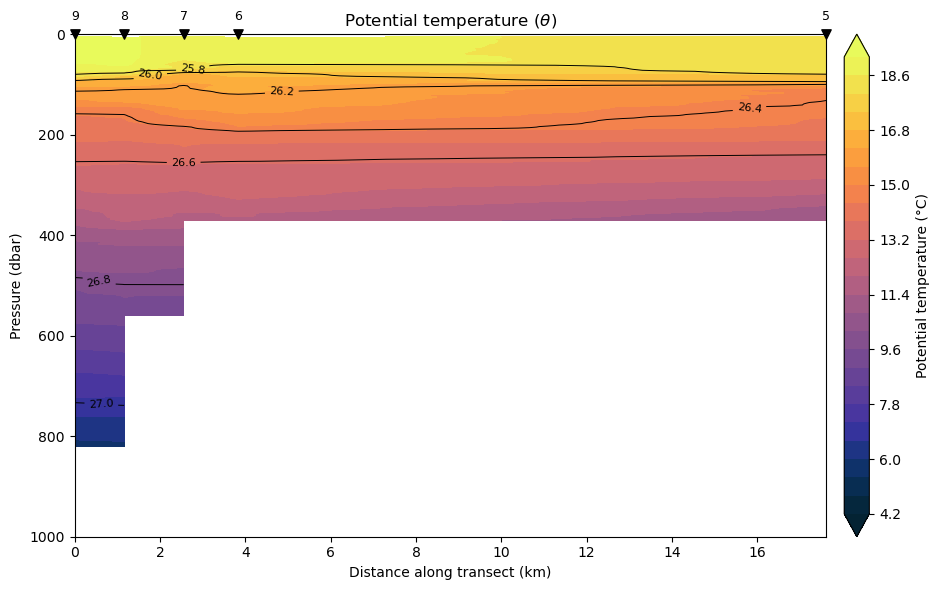

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))

# Reverse station order
station_data = station_data_ki[::-1]

# Recalculate distance in the reversed order
lons = np.array([d["lon"] for d in station_data])
lats = np.array([d["lat"] for d in station_data])

segment_distance = gsw.distance(lons, lats) / 1000
distance = np.concatenate(([0], np.cumsum(segment_distance)))

for d, dist in zip(station_data, distance):
    d["distance"] = dist

# Reverse the columns of the interpolated sections
theta_section_ki = theta_section_ki[:, ::-1]
salinity_section_ki = salinity_section_ki[:, ::-1]
sigma0_section_ki = sigma0_section_ki[:, ::-1]

print("Station order:", [d["station"] for d in station_data])


# Potential temperature
cf = ax.contourf(
    distance,
    pressure_grid_ki,
    theta_section_ki,
    levels=25,
    cmap=cmocean.cm.thermal,
    extend="both"
)

# Density contours
sigma_min = np.nanmin(sigma0_section_ki)
sigma_max = np.nanmax(sigma0_section_ki)

density_levels = np.arange(
    np.floor(sigma_min * 10) / 10,
    np.ceil(sigma_max * 10) / 10 + 0.05,
    0.2
)

cs = ax.contour(
    distance,
    pressure_grid_ki,
    sigma0_section_ki,
    levels=density_levels,
    colors="black",
    linewidths=0.7
)

ax.clabel(cs, inline=True, fontsize=8, fmt="%.1f")

# Station markers along the surface
ax.scatter(
    distance,
    np.zeros_like(distance),
    color="black",
    marker="v",
    s=45,
    zorder=5,
    clip_on=False
)

# Station labels
for d in station_data:
    ax.annotate(
        str(d["station"]),
        (d["distance"], 0),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        clip_on=False
    )

# Axes and title
ax.set_ylim(1000, 0)
ax.set_xlabel("Distance along transect (km)")
ax.set_ylabel("Pressure (dbar)")
ax.set_title("Potential temperature ($\\theta$)")

# Colourbar
cbar = fig.colorbar(cf, ax=ax, pad=0.02)
cbar.set_label("Potential temperature (°C)")

plt.tight_layout()
plt.show()

### Load and calculate Bonney Variables

In [10]:
os.chdir(r'C:\Users\nribeiro\OneDrive - University of Tasmania\IMOS Shared Docs\CAPSTAN 2025\Datasets\CTD Bonney') #Will need to change this 

In [11]:
# Find the KI CTD files
files_bon = sorted(Path(".").glob("in2026_t02*CtdAvg.nc"))

print(f"Found {len(files_bon)} files:")
for f in files_bon:
    print(f.name)

Found 5 files:
in2026_t02010CtdAvg.nc
in2026_t02011CtdAvg.nc
in2026_t02012CtdAvg.nc
in2026_t02013CtdAvg.nc
in2026_t02014CtdAvg.nc


In [12]:
station_data_bon = []

for f in files_bon:
    ds = xr.open_dataset(f)

    station = int(f.name.split("CtdAvg")[0][-3:])

    station_data_bon.append({
        "station": station,
        "lat": float(ds["latitude"].values.squeeze()),
        "lon": float(ds["longitude"].values.squeeze()),
        "pressure": ds["pressure"].values.squeeze(),
        "temperature": ds["temperature"].values.squeeze(),
        "salinity": ds["salinity"].values.squeeze()
    })

    ds.close()

In [13]:
print("Bonney CTD stations")
print("-" * 70)

for d in station_data_bon:
    p = np.asarray(d["pressure"])
    valid = np.isfinite(p)

    deepest = p[valid].max() if valid.any() else np.nan

    print(
        f"Station {d['station']:>3}: "
        f"Lon={d['lon']:.4f}, "
        f"Lat={d['lat']:.4f}, "
        f"Deepest pressure={deepest:.1f} dbar"
    )

Bonney CTD stations
----------------------------------------------------------------------
Station  10: Lon=140.9978, Lat=-38.8749, Deepest pressure=2674.6 dbar
Station  11: Lon=141.1673, Lat=-38.5821, Deepest pressure=370.7 dbar
Station  12: Lon=141.1477, Lat=-38.6152, Deepest pressure=861.7 dbar
Station  13: Lon=141.1316, Lat=-38.6438, Deepest pressure=1604.5 dbar
Station  14: Lon=141.1031, Lat=-38.7630, Deepest pressure=2120.6 dbar


## Calculate gsw variables

In [14]:
# ============================================================
# BONNEY — CALCULATE TEOS-10 VARIABLES
# ============================================================

for d in station_data_bon:

    SA = gsw.SA_from_SP(
        d["salinity"],
        d["pressure"],
        d["lon"],
        d["lat"]
    )

    CT = gsw.CT_from_t(
        SA,
        d["temperature"],
        d["pressure"]
    )

    theta = gsw.pt0_from_t(
        SA,
        d["temperature"],
        d["pressure"]
    )

    sigma0 = gsw.sigma0(SA, CT)

    d["SA"] = SA
    d["CT"] = CT
    d["theta"] = theta
    d["sigma0"] = sigma0

print("Bonney potential temperature and density calculated.")

Bonney potential temperature and density calculated.


### I will have to reorder the stations so they make sense. 

In [15]:

# ============================================================
# KANGAROO ISLAND — REBUILD PLOTTING DATA IN CORRECT ORDER
# Desired plotting order: 9 > 8 > 7 > 6
# ============================================================

# 1. Explicit station order for the CTD/LADCP comparison
ki_plot_order = [5, 9, 8, 7, 6]

# Look up the original station dictionaries
ki_by_station = {
    d["station"]: d for d in station_data_ki
}

ki_stations_plot = [
    ki_by_station[station] for station in ki_plot_order
]

# 2. Recalculate distance starting at station 9
lons_ki_plot = np.array([d["lon"] for d in ki_stations_plot])
lats_ki_plot = np.array([d["lat"] for d in ki_stations_plot])

segment_distance_ki_plot = gsw.distance(
    lons_ki_plot, lats_ki_plot
) / 1000

distance_ki_plot = np.concatenate([
    [0],
    np.cumsum(segment_distance_ki_plot)
])

for d, dist in zip(ki_stations_plot, distance_ki_plot):
    d["distance_ki_plot"] = dist

# 3. Rebuild interpolated sections in exactly the same order
theta_section_ki_plot = np.array([
    interp_profile(d["pressure"], d["theta"], pressure_grid_ki)
    for d in ki_stations_plot
]).T

salinity_section_ki_plot = np.array([
    interp_profile(d["pressure"], d["salinity"], pressure_grid_ki)
    for d in ki_stations_plot
]).T

sigma0_section_ki_plot = np.array([
    interp_profile(d["pressure"], d["sigma0"], pressure_grid_ki)
    for d in ki_stations_plot
]).T

# 4. Check station order and distances
print("KI plotting order:", [d["station"] for d in ki_stations_plot])
print("KI distances (km):", np.round(distance_ki_plot, 2))
print(f"Total KI plotting distance: {distance_ki_plot[-1]:.2f} km")


KI plotting order: [5, 9, 8, 7, 6]
KI distances (km): [ 0.    9.95 11.11 12.5  13.78]
Total KI plotting distance: 13.78 km


In [16]:
# 1. Explicitly order Bonney stations geographically
# ------------------------------------------------------------
bonney_order = [10, 14, 13, 12, 11]

bonney_by_station = {
    d["station"]: d for d in station_data_bon
}

station_data_bon = [
    bonney_by_station[station] for station in bonney_order
]

# ------------------------------------------------------------
# 2. Recalculate cumulative distance along the transect
# ------------------------------------------------------------
lons_bon = np.array([d["lon"] for d in station_data_bon])
lats_bon = np.array([d["lat"] for d in station_data_bon])

segment_distance_bon = gsw.distance(lons_bon, lats_bon) / 1000

distance_bon = np.concatenate([
    [0],
    np.cumsum(segment_distance_bon)
])

for d, dist in zip(station_data_bon, distance_bon):
    d["distance"] = dist

# ------------------------------------------------------------
# 3. Rebuild sections on the 0–2500 dbar grid
# ------------------------------------------------------------
pressure_grid_bon = np.arange(0, 2501, 1)

theta_section_bon = np.array([
    interp_profile(d["pressure"], d["theta"], pressure_grid_bon)
    for d in station_data_bon
]).T

salinity_section_bon = np.array([
    interp_profile(d["pressure"], d["salinity"], pressure_grid_bon)
    for d in station_data_bon
]).T

sigma0_section_bon = np.array([
    interp_profile(d["pressure"], d["sigma0"], pressure_grid_bon)
    for d in station_data_bon
]).T

# ------------------------------------------------------------
# 4. Check the result
# ------------------------------------------------------------
print("Station order:", [d["station"] for d in station_data_bon])
print("Cumulative distance (km):", np.round(distance_bon, 2))
print(f"Total Bonney distance: {distance_bon[-1]:.2f} km")
print("Temperature section shape:", theta_section_bon.shape)

Station order: [10, 14, 13, 12, 11]
Cumulative distance (km): [ 0.   15.43 28.91 32.39 36.44]
Total Bonney distance: 36.44 km
Temperature section shape: (2501, 5)


### Final Plot

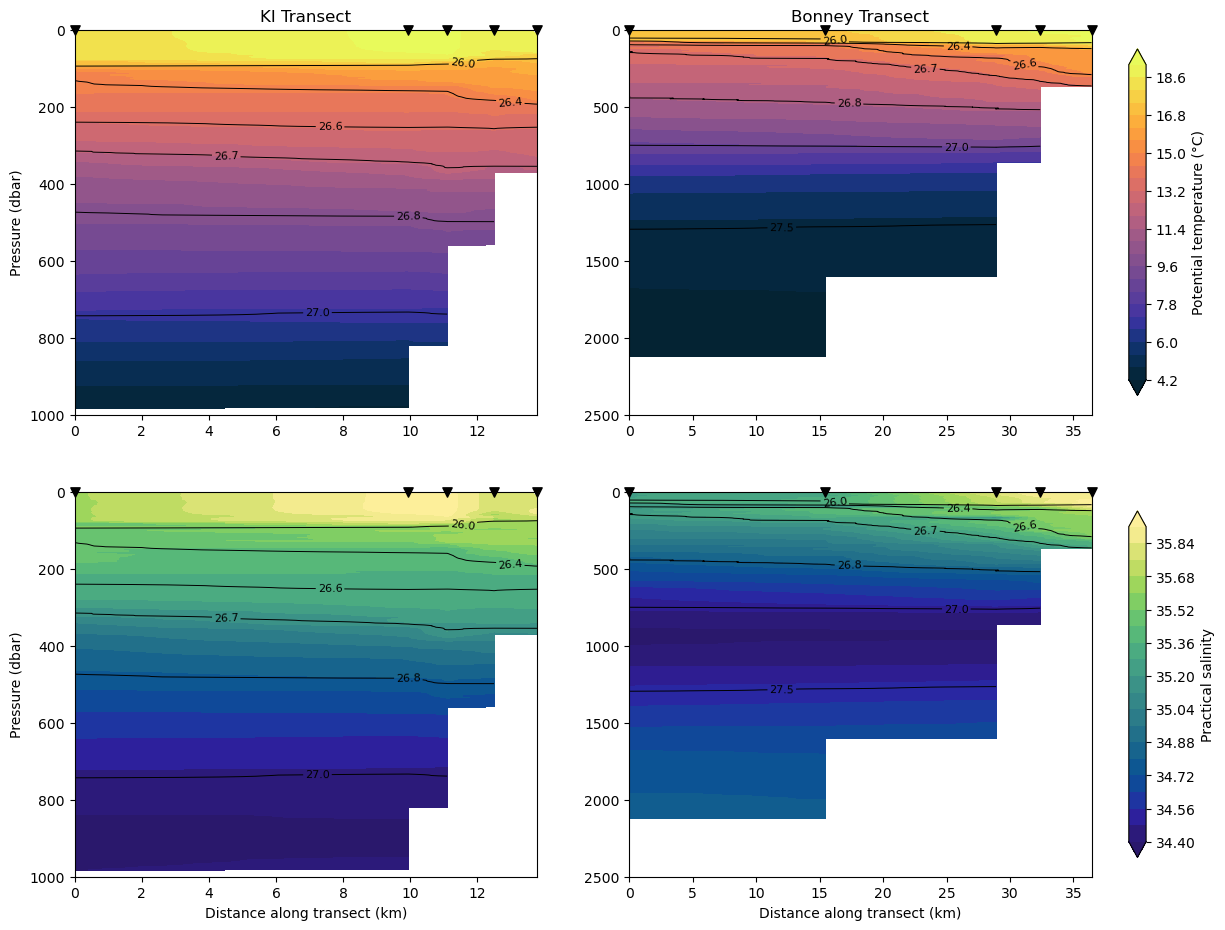

In [20]:

# ============================================================
# 2 x 2 TRANSECT FIGURE: KI AND BONNEY
# ============================================================

fig, axs = plt.subplots(
    2, 2,
    figsize=(16, 11),
    sharey=False
)

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

density_interval = 0.2

transects = {
    "KI": {
        "stations": ki_stations_plot,
        "distance": distance_ki_plot,
        "pressure": pressure_grid_ki,
        "theta": theta_section_ki_plot,
        "salinity": salinity_section_ki_plot,
        "sigma0": sigma0_section_ki_plot,
    },
    "Bonney": {
        "stations": station_data_bon,
        "distance": distance_bon,
        "pressure": pressure_grid_bon,
        "theta": theta_section_bon,
        "salinity": salinity_section_bon,
        "sigma0": sigma0_section_bon,
    }
}


def plot_transect(
    ax, data, variable, cmap, title, colourbar_label, pressure_max
):
    distance = data["distance"]
    pressure = data["pressure"]
    values = data[variable]
    sigma0 = data["sigma0"]
    stations = data["stations"]

    cf = ax.contourf(
        distance, pressure, values,
        levels=25, cmap=cmap, extend="both"
    )

    # --------------------------------------------------------
    # Density contours
    # --------------------------------------------------------

    # Automatic density levels (optional)
    # sigma_min = np.nanmin(sigma0)
    # sigma_max = np.nanmax(sigma0)
    #
    # density_levels = np.arange(
    #     np.ceil(sigma_min / density_interval) * density_interval,
    #     sigma_max + density_interval * 0.5,
    #     density_interval
    # )

    # Manually specified density levels
    density_levels = [
        26.0, 26.4, 26.6, 26.7, 26.8, 27.0, 27.5, 28.0
    ]

    cs = ax.contour(
        distance, pressure, sigma0,
        levels=density_levels,
        colors="black",
        linewidths=0.7
    )

    ax.clabel(
        cs,
        inline=True,
        fontsize=8,
        fmt="%.1f"
    )

    # --------------------------------------------------------
    # Station markers
    # --------------------------------------------------------

    ax.scatter(
        distance, np.zeros_like(distance),
        color="black",
        marker="v",
        s=45,
        zorder=5,
        clip_on=False
    )

    # Station labels (optional)
    # for d in stations:
    #     ax.annotate(
    #         str(d["station"]),
    #         (d["distance_ki_plot"], 0),
    #         xytext=(0, 8),
    #         textcoords="offset points",
    #         ha="center",
    #         va="bottom",
    #         fontsize=9,
    #         clip_on=False
    #     )

    ax.set_ylim(pressure_max, 0)
    ax.set_xlabel("Distance along transect (km)")
    ax.set_title(title)

    return cf


# ------------------------------------------------------------
# POTENTIAL TEMPERATURE
# ------------------------------------------------------------

cf1 = plot_transect(
    axs[0, 0],
    transects["KI"],
    "theta",
    cmocean.cm.thermal,
    "KI Transect",
    "Potential temperature (°C)",
    pressure_max=1000
)

cf2 = plot_transect(
    axs[0, 1],
    transects["Bonney"],
    "theta",
    cmocean.cm.thermal,
    "Bonney Transect",
    "Potential temperature (°C)",
    pressure_max=2500
)


# ------------------------------------------------------------
# SALINITY
# ------------------------------------------------------------

cf3 = plot_transect(
    axs[1, 0],
    transects["KI"],
    "salinity",
    cmocean.cm.haline,
    "",
    "Practical salinity",
    pressure_max=1000
)

cf4 = plot_transect(
    axs[1, 1],
    transects["Bonney"],
    "salinity",
    cmocean.cm.haline,
    "",
    "Practical salinity",
    pressure_max=2500
)


# ------------------------------------------------------------
# LABELS AND COLOURBARS
# ------------------------------------------------------------

axs[0, 0].set_ylabel("Pressure (dbar)")
axs[1, 0].set_ylabel("Pressure (dbar)")

# Remove x-axis labels from the top row only
axs[0, 0].set_xlabel("")
axs[0, 1].set_xlabel("")

cbar_t = fig.colorbar(
    cf1,
    ax=[axs[0, 0], axs[0, 1]],
    pad=0.03,
    shrink=0.9
)
cbar_t.set_label("Potential temperature (°C)")

cbar_s = fig.colorbar(
    cf3,
    ax=[axs[1, 0], axs[1, 1]],
    pad=0.03,
    shrink=0.9
)
cbar_s.set_label("Practical salinity")

plt.savefig(
    r"C:\Users\nribeiro\OneDrive - University of Tasmania\IMOS Shared Docs\CAPSTAN 2025\CAPSTAN_HAB_work\Figures\T&S_transects.png",
    bbox_inches="tight"
)

plt.show()


### Save the density contours calculated here to use with other plots: 

In [ ]:
# Example structure; dimensions and arrays must match your actual variables
ds_density = xr.Dataset(
    {
        "sigma0_KI": (
            ("pressure_ki", "station_ki"),
            sigma0_section_ki_plot
        ),
        "sigma0_Bonney": (
            ("pressure_bon", "station_bon"),
            sigma0_section_bon
        ),
    },
    coords={
        "pressure_ki": pressure_grid_ki,
        "station_ki": [d["station"] for d in ki_stations_plot],
        "pressure_bon": pressure_grid_bon,
        "station_bon": [d["station"] for d in station_data_bon],
    }
)

ds_density.to_netcdf("CTD_density_sections.nc")